# FloodVerify CV: report figures
Runtime: **CPU** (no GPU units). Sections 1-6 read results already on Drive (a few minutes). Section 7 copies the images
(10-15 min) and runs the Gate 2 model on 4 crops on the CPU. Every figure is saved as PNG (200 dpi) to `figures/` on Drive.

Run this after the second account's M0 seeds (and M2) have finished, so the seed figure includes them; missing runs are
simply left out.

Figures 7 and 8 show xBD imagery. Caption them with the source: *Imagery: xBD (Gupta et al., 2019), Maxar; CC BY-NC-SA.*
Do not put the PNGs in the public repo.

## 0. Setup and style

In [1]:
from google.colab import drive
drive.mount("/content/drive")
D = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
CK, OUT, FIG = f"{D}/checkpoints", f"{D}/eval_extras", f"{D}/figures"
X, MAN = "/content/xbd", "/content/xbd/rscc_flood_manifest.csv"
!mkdir -p "{FIG}"
%cd /content
!rm -rf /content/FloodVerify
!git clone -q -b m3/eval-extras https://github.com/aaarrvind/FloodVerify.git /content/FloodVerify
import sys; sys.path.insert(0, "/content/FloodVerify/src")

Mounted at /content/drive
/content


In [2]:
import json, os, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from floodsitrep.cv.eval import metrics as M

# Colours: fixed categorical order (blue, orange, aqua, yellow), one per model, never cycled.
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODELS = {  # key -> (label, colour, run prefix)
    "m1_ce": ("M1 siamese, weighted CE", "#2a78d6", "m1_siamese_unet_ce"),
    "m1_df": ("M1 siamese, Dice + focal", "#eb6834", "m1_siamese_unet"),
    "m0_df": ("M0 early fusion, Dice + focal", "#1baf7a", "m0_early_fusion_unet"),
    "m2_ce": ("M2 siamese SegFormer, weighted CE", "#eda100", "m2_siamese_segformer_ce"),
}
BLUE = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # one sequential hue, light -> dark
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False})

def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=200, bbox_inches="tight"); plt.show(); print("saved", f"figures/{name}.png")

def log(run):
    p = f"{CK}/{run}/metrics.jsonl"
    return pd.DataFrame([json.loads(l) for l in open(p)]) if os.path.exists(p) else None

def best(df):
    return df.loc[df["xview2_pixel_score"].idxmax()]
print({k: [s for s in range(3) if log(f"{v[2]}_s{s}") is not None] for k, v in MODELS.items()})  # seeds found

{'m1_ce': [0, 1, 2], 'm1_df': [0, 1, 2], 'm0_df': [0, 1, 2], 'm2_ce': [0, 1, 2]}


## 1. Training curves (seed 0)

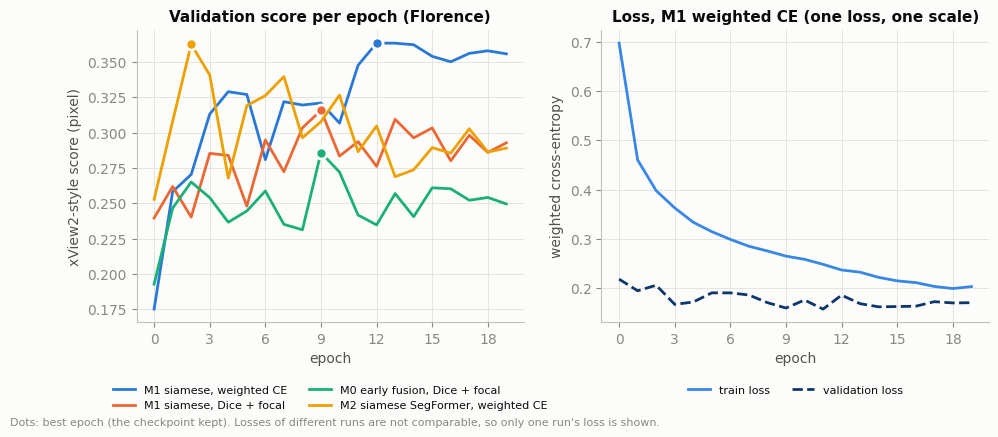

saved figures/fig1_training_curves.png


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
for key in ("m1_ce", "m1_df", "m0_df", "m2_ce"):
    lab, col, pre = MODELS[key]; df = log(f"{pre}_s0")
    if df is None: continue
    a.plot(df.epoch, df.xview2_pixel_score, color=col, label=lab)
    bb = best(df); a.plot(bb.epoch, bb.xview2_pixel_score, "o", color=col, ms=8, mec=SURF, mew=2)
a.set(title="Validation score per epoch (Florence)", xlabel="epoch", ylabel="xView2-style score (pixel)")
a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8, ncol=2)
a.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
df = log("m1_siamese_unet_ce_s0")
b.plot(df.epoch, df.train_loss, color=BLUE[2], label="train loss")
b.plot(df.epoch, df.val_loss, color=BLUE[4], ls="--", label="validation loss")
b.set(title="Loss, M1 weighted CE (one loss, one scale)", xlabel="epoch", ylabel="weighted cross-entropy")
b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8, ncol=2)
b.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
fig.text(0.01, -0.16, "Dots: best epoch (the checkpoint kept). Losses of different runs are not comparable, so only one run's loss is shown.",
         color=MUTED, fontsize=8)
save(fig, "fig1_training_curves")

## 2. Seeds: score and destroyed F1 per run (best epoch of each run)

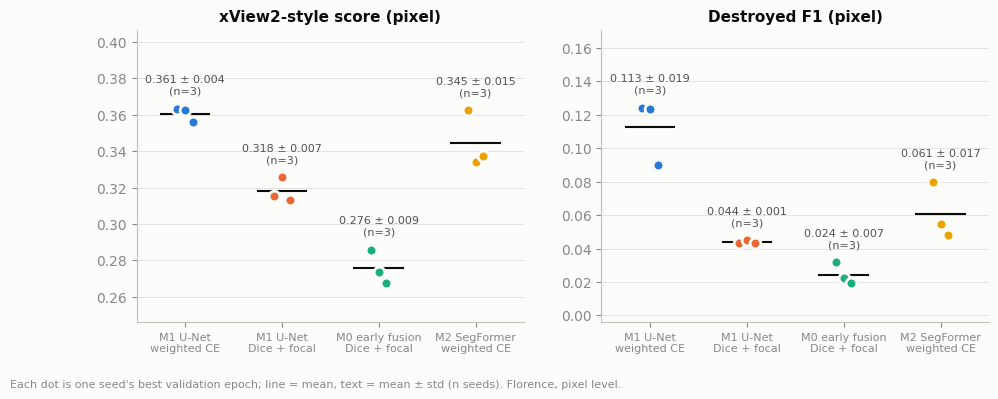

saved figures/fig2_seeds.png


,key,seed,score,destroyed
0,m1_ce,0,0.3633,0.1241
1,m1_ce,1,0.3626,0.1234
2,m1_ce,2,0.3561,0.0901
3,m1_df,0,0.3157,0.0431
4,m1_df,1,0.3258,0.0449
5,m1_df,2,0.3132,0.0436
6,m0_df,0,0.2858,0.0317
7,m0_df,1,0.2738,0.0222
8,m0_df,2,0.2677,0.0192
9,m2_ce,0,0.3624,0.0797


In [14]:
rows = []
for key, (lab, col, pre) in MODELS.items():
    for s in range(3):
        df = log(f"{pre}_s{s}")
        if df is not None:
            bb = best(df); rows.append({"key": key, "seed": s, "score": bb.xview2_pixel_score, "destroyed": bb.dmg_f1_destroyed})
T = pd.DataFrame(rows)
keys = [k for k in MODELS if k in set(T.key)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col_name, title in [(axes[0], "score", "xView2-style score (pixel)"), (axes[1], "destroyed", "Destroyed F1 (pixel)")]:
    for i, key in enumerate(keys):
        lab, colr, _ = MODELS[key]; v = T[T.key == key][col_name].values
        ax.scatter(np.full(len(v), i) + np.linspace(-0.08, 0.08, len(v)), v, s=60, color=colr, edgecolor=SURF, linewidth=2, zorder=3)
        ax.plot([i - 0.25, i + 0.25], [v.mean()] * 2, color=INK, lw=1.5)
        txt = f"{v.mean():.3f}" + (f" ± {v.std(ddof=1):.3f}" if len(v) > 1 else "") + f"\n(n={len(v)})"
        ax.annotate(txt, (i, v.max()), xytext=(0, 9), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK2)
    SHORT = {"m1_ce": "M1 U-Net\nweighted CE", "m1_df": "M1 U-Net\nDice + focal",
             "m0_df": "M0 early fusion\nDice + focal", "m2_ce": "M2 SegFormer\nweighted CE"}
    ax.set_xticks(range(len(keys)), [SHORT[k] for k in keys], fontsize=8)
    lo, hi = T[col_name].min(), T[col_name].max(); pad = (hi - lo) * 0.35 + 0.01
    ax.set_ylim(lo - pad * 0.5, hi + pad); ax.set_xlim(-0.5, len(keys) - 0.5); ax.set_title(title); ax.grid(axis="x", visible=False)
fig.text(0.01, -0.06, "Each dot is one seed's best validation epoch; line = mean, text = mean ± std (n seeds). Florence, pixel level.",
         color=MUTED, fontsize=8)
save(fig, "fig2_seeds")
T.round(4)

## 3. Per-class F1 (pixel level; mean over available seeds, bars show ± std)

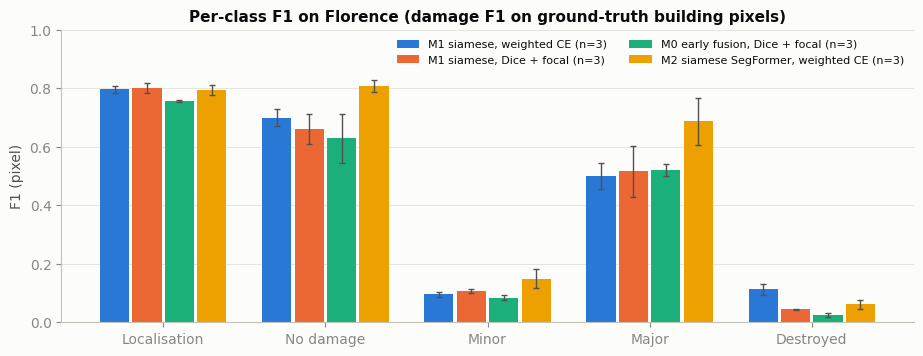

saved figures/fig3_per_class_f1.png


In [5]:
metrics_ = [("loc_f1", "Localisation"), ("dmg_f1_no_damage", "No damage"), ("dmg_f1_minor", "Minor"),
            ("dmg_f1_major", "Major"), ("dmg_f1_destroyed", "Destroyed")]
fig, ax = plt.subplots(figsize=(11, 3.8)); w = 0.8 / len(keys)
for j, key in enumerate(keys):
    lab, colr, pre = MODELS[key]
    bests = [best(log(f"{pre}_s{s}")) for s in range(3) if log(f"{pre}_s{s}") is not None]
    m = [np.mean([b[k] for b in bests]) for k, _ in metrics_]
    sd = [np.std([b[k] for b in bests], ddof=1) if len(bests) > 1 else 0 for k, _ in metrics_]
    x = np.arange(len(metrics_)) + (j - (len(keys) - 1) / 2) * w
    ax.bar(x, m, width=w - 0.02, color=colr, label=f"{lab} (n={len(bests)})", yerr=sd, error_kw={"ecolor": INK2, "lw": 1, "capsize": 2})
ax.set_xticks(range(len(metrics_)), [n for _, n in metrics_]); ax.set_ylabel("F1 (pixel)"); ax.set_ylim(0, 1)
ax.set_title("Per-class F1 on Florence (damage F1 on ground-truth building pixels)"); ax.legend(fontsize=8, ncol=2); ax.grid(axis="x", visible=False)
save(fig, "fig3_per_class_f1")

## 4. Where predictions go: pixel and building confusion (Gate 2 model, rows sum to 100%)

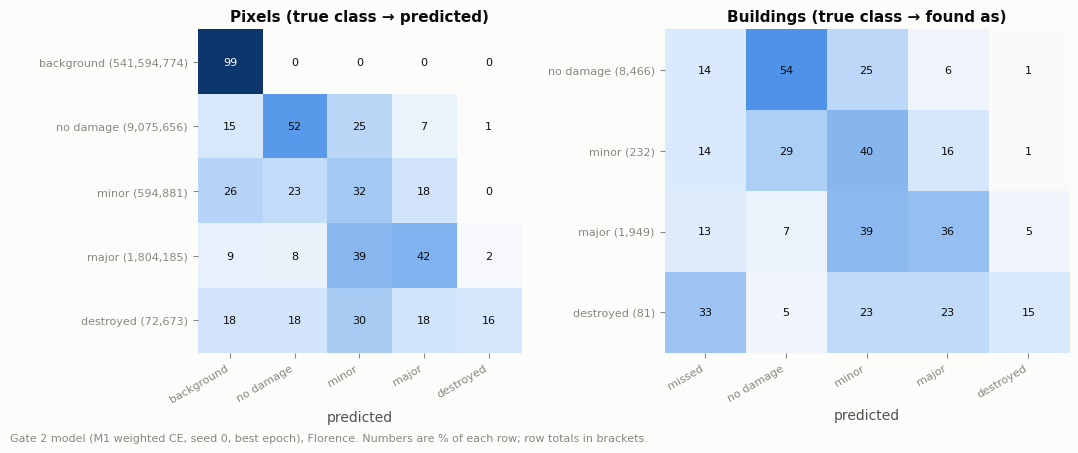

saved figures/fig4_confusion.png


In [6]:
names = ["background", "no damage", "minor", "major", "destroyed"]
cm = np.array(best(log("m1_siamese_unet_ce_s0"))["val_confusion"], float)
P = cm / cm.sum(1, keepdims=True) * 100
bl = np.load(f"{OUT}/bl_m1_siamese_unet_ce_s0_val_f1.npz")["bcms"].sum(0).astype(float)
Bp = bl / bl.sum(1, keepdims=True) * 100
cmap = mpl.colors.LinearSegmentedColormap.from_list("blue", [SURF] + BLUE)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [5, 5]})
for ax, Mx, rows_, cols_, title, counts in [
        (a, P, names, names, "Pixels (true class → predicted)", cm.sum(1)),
        (b, Bp, names[1:], ["missed"] + names[1:], "Buildings (true class → found as)", bl.sum(1))]:
    ax.imshow(Mx, cmap=cmap, vmin=0, vmax=100); ax.grid(False)
    for i in range(Mx.shape[0]):
        for j in range(Mx.shape[1]):
            ax.text(j, i, f"{Mx[i, j]:.0f}", ha="center", va="center", fontsize=8, color="#ffffff" if Mx[i, j] > 55 else INK)
    ax.set_xticks(range(len(cols_)), cols_, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(rows_)), [f"{r} ({int(c):,})" for r, c in zip(rows_, counts)], fontsize=8)
    ax.set_title(title); ax.set_xlabel("predicted"); ax.spines[:].set_visible(False)
fig.text(0.01, -0.1, "Gate 2 model (M1 weighted CE, seed 0, best epoch), Florence. Numbers are % of each row; row totals in brackets.",
         color=MUTED, fontsize=8)
save(fig, "fig4_confusion")

## 5. Calibration on predicted-building pixels (reliability diagram)

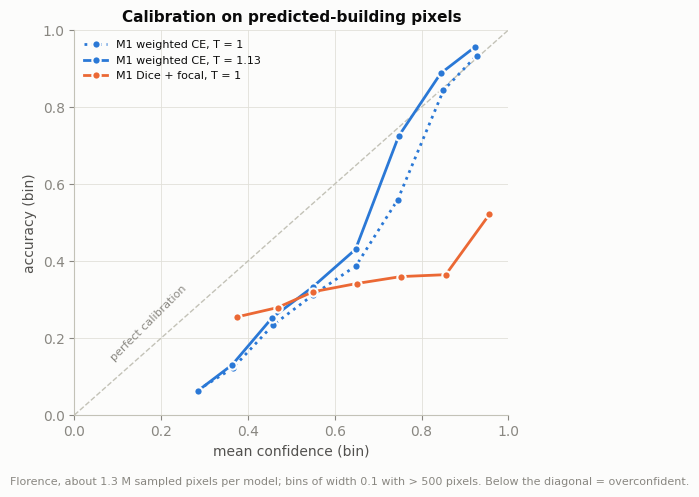

saved figures/fig5_reliability.png


In [15]:
def soft(z, t):
    z = z / t; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
T_all = json.load(open(f"{CK}/m1_siamese_unet_ce_s0/temperature.json"))["temperature"]
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--"); ax.text(0.08, 0.14, "perfect calibration", color=MUTED, fontsize=8, rotation=45)
for run, t, colr, lab, ls in [("m1_siamese_unet_ce_s0", 1.0, MODELS["m1_ce"][1], "M1 weighted CE, T = 1", ":"),
                              ("m1_siamese_unet_ce_s0", T_all, MODELS["m1_ce"][1], f"M1 weighted CE, T = {T_all:.2f}", "-"),
                              ("m1_siamese_unet_s0", 1.0, MODELS["m1_df"][1], "M1 Dice + focal, T = 1", "-")]:
    r = np.load(f"{OUT}/{run}_val.npz")
    p = soft(r["bld_logits"].astype(np.float64), t); conf, ok = p.max(1), p.argmax(1) == r["bld_labels"]
    bins = np.clip((conf * 10).astype(int), 0, 9)
    xs = [conf[bins == k].mean() for k in range(10) if (bins == k).sum() > 500]
    ys = [ok[bins == k].mean() for k in range(10) if (bins == k).sum() > 500]
    ax.plot(xs, ys, ls, marker="o", ms=6, color=colr, mec=SURF, mew=1.5, label=lab)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean confidence (bin)", ylabel="accuracy (bin)",
       title="Calibration on predicted-building pixels")
ax.legend(fontsize=8, loc="upper left")
fig.text(0.01, -0.03, "Florence, about 1.3 M sampled pixels per model; bins of width 0.1 with > 500 pixels. Below the diagonal = overconfident.",
         color=MUTED, fontsize=8)
save(fig, "fig5_reliability")

## 6. Resolution ladder (Gate 2 model, not retrained)

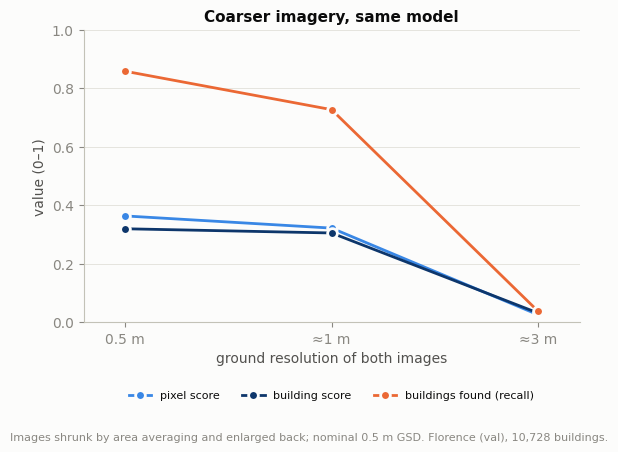

saved figures/fig6_resolution_ladder.png


In [16]:
import floodsitrep.cv.eval.building_level as B
xs, labels = [0.5, 1, 3], ["0.5 m", "≈1 m", "≈3 m"]
ser = {"pixel score": [], "building score": [], "buildings found (recall)": []}
for f in (1, 2, 6):
    r = np.load(f"{OUT}/bl_m1_siamese_unet_ce_s0_val_f{f}.npz")
    b = B.summarise_buildings(r["bcms"].sum(0), r["comps"].sum(), r["falses"].sum())
    ser["pixel score"].append(M.flat(M.summarise(r["crop_cms"].sum(0)))["xview2_pixel_score"])
    ser["building score"].append(b["xview2_building_score"]); ser["buildings found (recall)"].append(b["loc_recall"])
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for (name, v), colr in zip(ser.items(), [BLUE[2], BLUE[4], "#eb6834"]):
    ax.plot(range(3), v, marker="o", ms=7, color=colr, mec=SURF, mew=2, label=name)
ax.set_xticks(range(3), labels); ax.set_xlim(-0.2, 2.2); ax.set_ylim(0, 1)
ax.set(xlabel="ground resolution of both images", ylabel="value (0–1)", title="Coarser imagery, same model")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3); ax.grid(axis="x", visible=False)
fig.text(0.01, -0.2, "Images shrunk by area averaging and enlarged back; nominal 0.5 m GSD. Florence (val), 10,728 buildings.",
         color=MUTED, fontsize=8)
save(fig, "fig6_resolution_ladder")

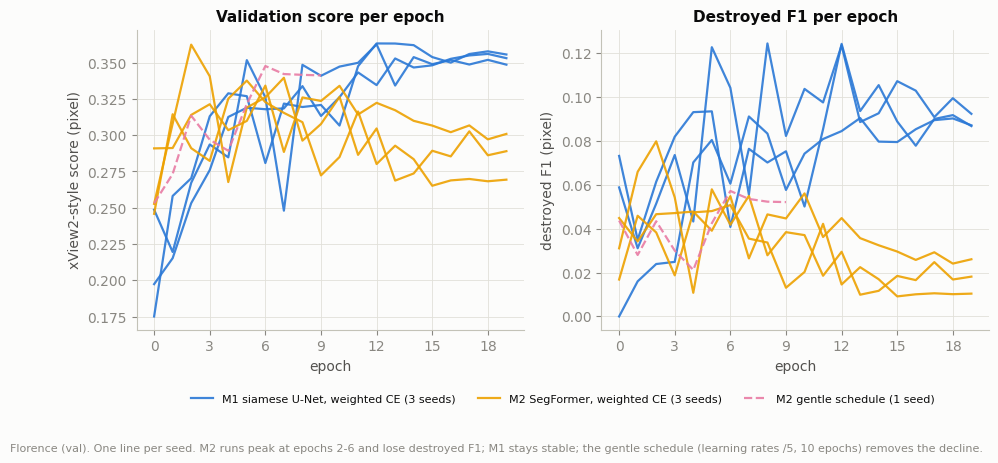

saved figures/fig9_m2_early_peak.png


In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.9))
groups = [("M1 siamese U-Net, weighted CE (3 seeds)", "m1_siamese_unet_ce", MODELS["m1_ce"][1], "-"),
          ("M2 SegFormer, weighted CE (3 seeds)", "m2_siamese_segformer_ce", MODELS["m2_ce"][1], "-"),
          ("M2 gentle schedule (1 seed)", "m2_siamese_segformer_gentle_ce", "#e87ba4", "--")]
for lab, pre, colr, ls in groups:
    first = True
    for s in range(3):
        df = log(f"{pre}_s{s}")
        if df is None: continue
        for ax, col in ((a, "xview2_pixel_score"), (b, "dmg_f1_destroyed")):
            ax.plot(df.epoch, df[col], ls, color=colr, lw=1.6, alpha=0.9, label=lab if (first and ax is a) else None)
        first = False
a.set(title="Validation score per epoch", xlabel="epoch", ylabel="xView2-style score (pixel)")
b.set(title="Destroyed F1 per epoch", xlabel="epoch", ylabel="destroyed F1 (pixel)")
for ax in (a, b): ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
a.legend(loc="upper center", bbox_to_anchor=(1.1, -0.18), fontsize=8, ncol=3)
fig.text(0.01, -0.2, "Florence (val). One line per seed. M2 runs peak at epochs 2-6 and lose destroyed F1; M1 stays stable; "
         "the gentle schedule (learning rates /5, 10 epochs) removes the decline.", color=MUTED, fontsize=8)
save(fig, "fig9_m2_early_peak")

## 7. Example predictions and one evidence grid (copies images, then runs the model on 4 crops on the CPU)
Crops are chosen by rule, not by eye: the two with the most destroyed pixels, the one with the most major pixels,
and the one with the most building pixels overall.

In [9]:
if not os.path.exists(f"{X}/processed/evidence_labels"):
    !mkdir -p /content/xbd/processed
    !tar -xf "{D}/xbd_tars/train_images_labels_targets.tar" -C /content/xbd
    !tar -xf "{D}/xbd_tars/test_images_labels_targets.tar" -C /content/xbd
    !cp -r "{D}/xbd/hold" /content/xbd/
    !cp "{D}/xbd/rscc_flood_manifest.csv" /content/xbd/
    !unzip -q "{D}/xbd/processed.zip" -d /content/xbd/processed
!ls /content/xbd

hold  processed  rscc_flood_manifest.csv  test	train


[np.str_('hurricane-florence_00000143_p2'), np.str_('hurricane-florence_00000475_p3'), np.str_('hurricane-florence_00000438_p1'), np.str_('hurricane-florence_00000430_p3')]


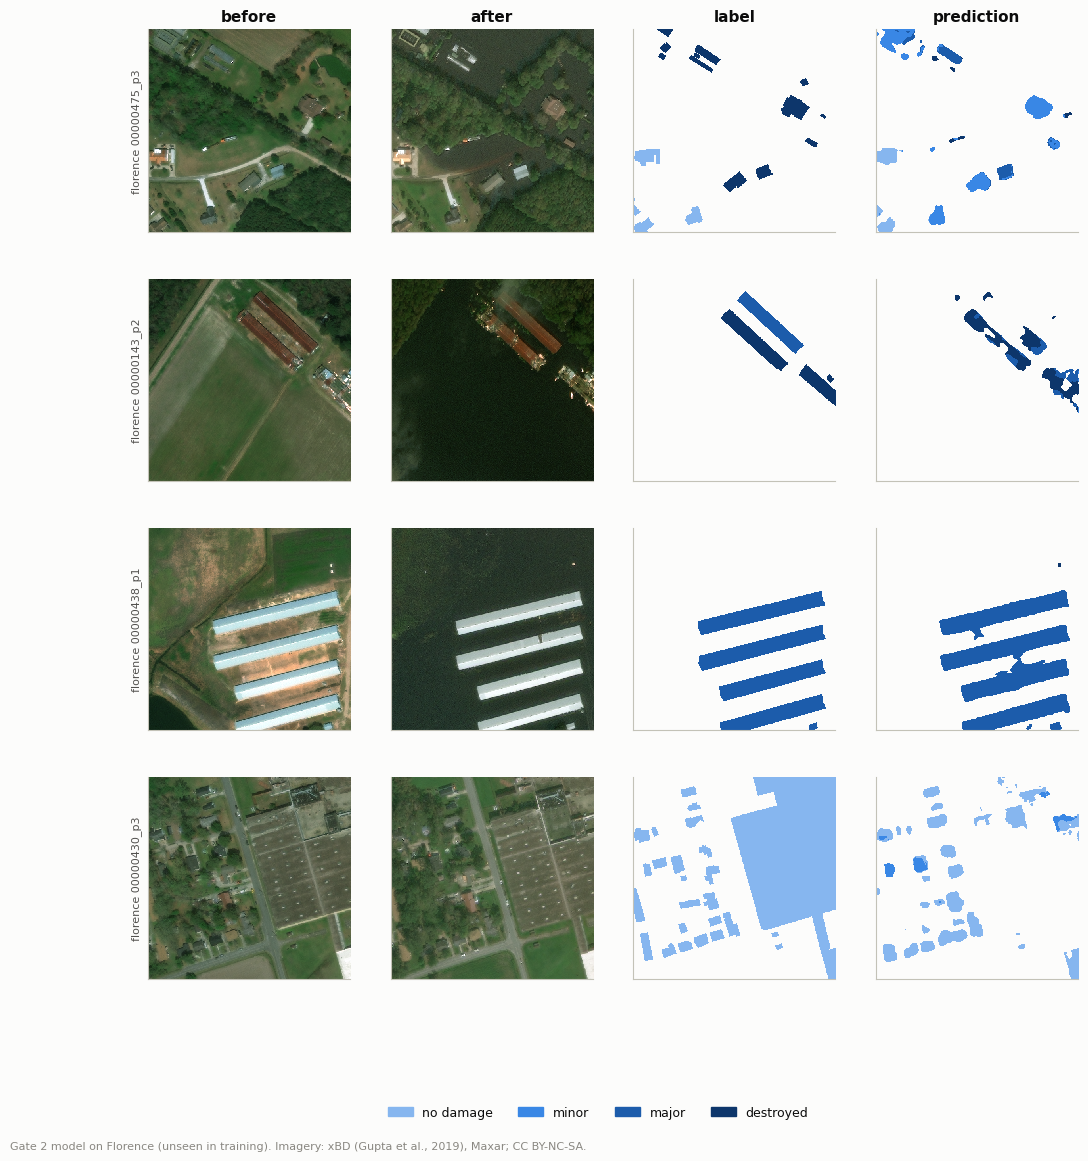

saved figures/fig7_example_predictions.png


In [11]:
import torch
from floodsitrep.cv.models import load_checkpoint
from floodsitrep.data.dataset import XbdTiles
r = np.load(f"{OUT}/bl_m1_siamese_unet_ce_s0_val_f1.npz")
ids, cms = list(r["crop_ids"]), r["crop_cms"]
truth = cms.sum(2)                          # pixels per true class, per crop
pick = list(np.argsort(-truth[:, 4])[:2]) + [int(np.argmax(truth[:, 3]))] + [int(np.argmax(truth[:, 1:].sum(1)))]
pick = list(dict.fromkeys(pick))[:4]
chosen = [ids[i] for i in pick]; print(chosen)
model, _ = load_checkpoint(f"{CK}/m1_siamese_unet_ce_s0/best.pt", "cpu")
ds = XbdTiles(X, MAN, role="val"); ds.rows = [row for row in ds.rows if f"{row['event']}_{row['tile_id']}_p{row['part']}" in chosen]
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
def show(t): return np.clip(t.permute(1, 2, 0).numpy() * std + mean, 0, 1)
mcmap = mpl.colors.ListedColormap([SURF, BLUE[1], BLUE[2], BLUE[3], BLUE[4]])
fig, axes = plt.subplots(len(ds), 4, figsize=(12, 3.1 * len(ds)))
for k in range(len(ds)):
    it = ds[k]
    with torch.no_grad():
        pred = model(it["pre"][None], it["post"][None]).argmax(1)[0].numpy()
    m = it["mask"].numpy().copy(); m[~it["valid"].numpy()] = 0; pred[~it["valid"].numpy()] = 0
    for j, (img, title) in enumerate([(show(it["pre"]), "before"), (show(it["post"]), "after"), (m, "label"), (pred, "prediction")]):
        ax = axes[k, j]; ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
        ax.imshow(img, cmap=mcmap if j > 1 else None, vmin=0, vmax=4, interpolation="nearest")
        if k == 0: ax.set_title(title)
    axes[k, 0].set_ylabel(it["tile_id"].replace("hurricane-florence_", "florence "), fontsize=8)
handles = [mpl.patches.Patch(color=BLUE[i], label=n) for i, n in zip(range(1, 5), ["no damage", "minor", "major", "destroyed"])]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.text(0.01, -0.025, "Gate 2 model on Florence (unseen in training). Imagery: xBD (Gupta et al., 2019), Maxar; CC BY-NC-SA.", color=MUTED, fontsize=8)
save(fig, "fig7_example_predictions")

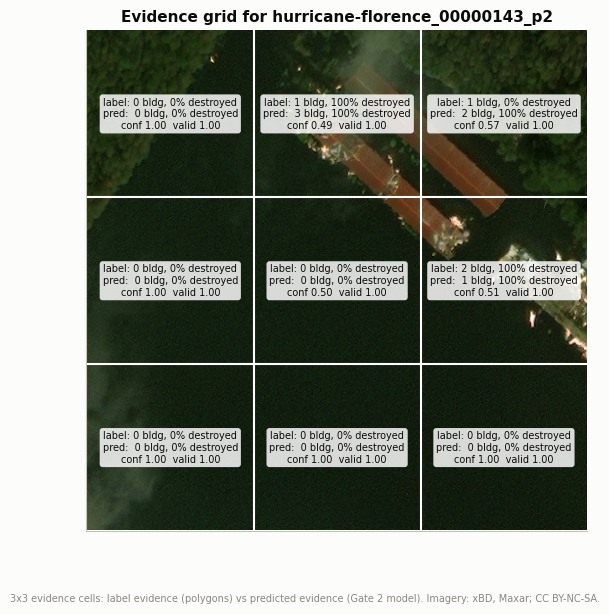

saved figures/fig8_evidence_grid.png


In [12]:
# Figure 8: one evidence grid: label vs predicted building counts per cell, drawn on the after image
tid = chosen[0]; it = ds[[f"{row['event']}_{row['tile_id']}_p{row['part']}" for row in ds.rows].index(tid)]
L = json.load(open(f"{X}/processed/evidence_labels/{tid}.json"))
P = json.load(open(f"{D}/evidence_predicted/m1_siamese_unet_ce_s0/{tid}.json"))
fig, ax = plt.subplots(figsize=(6.5, 6.5)); ax.imshow(show(it["post"])); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for v in (512 / 3, 1024 / 3):
    ax.axvline(v, color="#ffffff", lw=1.5); ax.axhline(v, color="#ffffff", lw=1.5)
for i, (lc, pc) in enumerate(zip(L["cells"], P["cells"])):
    r_, c_ = divmod(i, 3)
    txt = (f"label: {lc['buildings']} bldg, {lc['class_fraction']['destroyed']:.0%} destroyed\n"
           f"pred:  {pc['buildings']} bldg, {pc['class_fraction']['destroyed']:.0%} destroyed\n"
           f"conf {pc['confidence']:.2f}  valid {pc.get('valid_fraction', 1):.2f}")
    ax.text((c_ + 0.5) * 512 / 3, (r_ + 0.5) * 512 / 3, txt, ha="center", va="center", fontsize=7, color=INK,
            bbox={"boxstyle": "round,pad=0.3", "fc": SURF, "ec": "none", "alpha": 0.85})
ax.set_title(f"Evidence grid for {tid}")
fig.text(0.01, 0.0, "3x3 evidence cells: label evidence (polygons) vs predicted evidence (Gate 2 model). Imagery: xBD, Maxar; CC BY-NC-SA.",
         color=MUTED, fontsize=7)
save(fig, "fig8_evidence_grid")

## Done
All figures are in `figures/` on Drive. Paste a screenshot of any that look wrong.

In [17]:
!ls -la "{FIG}"

total 4732
drwx------  2 root root    4096 Nov 18 09:44 .
drwx------ 10 root root    4096 Nov 18 08:47 ..
-rw-------  1 root root  224276 Nov 18 08:48 fig1_training_curves.png
-rw-------  1 root root  122558 Nov 18 09:41 fig2_seeds.png
-rw-------  1 root root   72877 Nov 18 08:50 fig3_per_class_f1.png
-rw-------  1 root root  143796 Nov 18 08:56 fig4_confusion.png
-rw-------  1 root root  129957 Nov 18 09:43 fig5_reliability.png
-rw-------  1 root root   94381 Nov 18 09:44 fig6_resolution_ladder.png
-rw-------  1 root root 2554938 Nov 18 09:13 fig7_example_predictions.png
-rw-------  1 root root 1145501 Nov 18 09:14 fig8_evidence_grid.png
-rw-------  1 root root  346123 Nov 18 09:10 fig9_m2_early_peak.png
